# House Price Prediction

## Data Preprocessing and Feature Engineering

This notebook prepares the Ames Housing dataset for
machine learning by analyzing missing values,
selecting relevant features, encoding categorical
variables and splitting the dataset into training
and testing sets.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data_path = Path("data/house_prices.csv")

if not data_path.exists():
    data_path = Path("../data/house_prices.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset shape:", df.shape)

Duplicate rows: 0
Dataset shape: (1460, 81)


In [4]:
numeric_df = df.select_dtypes(include=np.number)

correlations = numeric_df.corr()["SalePrice"]

correlations = correlations.sort_values(
    ascending=False
)

correlations.head(15)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

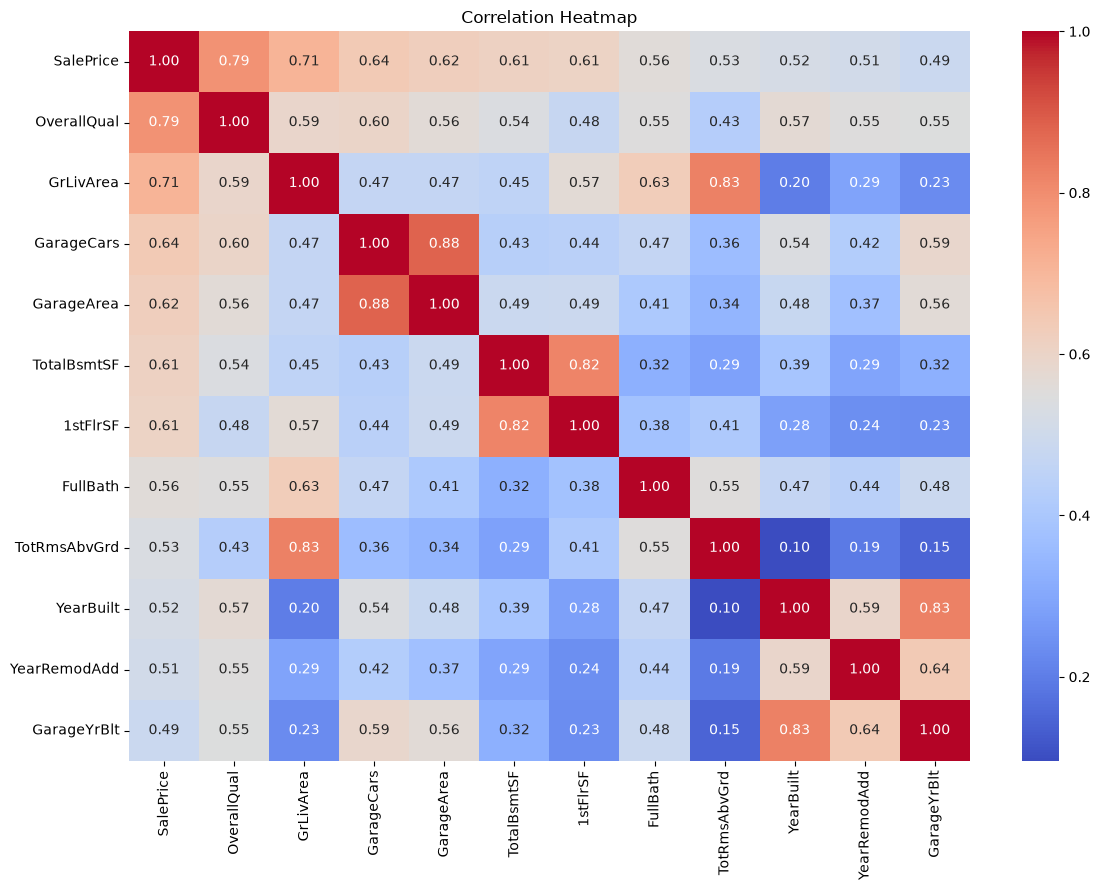

In [5]:
top_features = correlations.head(12).index

plt.figure(figsize=(12, 9))

sns.heatmap(
    numeric_df[top_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [6]:
features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "FullBath",
    "YearBuilt",
    "YearRemodAdd",
    "BedroomAbvGr",
    "LotArea",
    "Neighborhood",
    "HouseStyle",
    "ExterQual"
]

X = df[features].copy()
y = df["SalePrice"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Features shape: (1460, 12)
Target shape: (1460,)


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,FullBath,YearBuilt,YearRemodAdd,BedroomAbvGr,LotArea,Neighborhood,HouseStyle,ExterQual
0,7,1710,2,856,2,2003,2003,3,8450,CollgCr,2Story,Gd
1,6,1262,2,1262,2,1976,1976,3,9600,Veenker,1Story,TA
2,7,1786,2,920,2,2001,2002,3,11250,CollgCr,2Story,Gd
3,7,1717,3,756,1,1915,1970,3,9550,Crawfor,2Story,TA
4,8,2198,3,1145,2,2000,2000,4,14260,NoRidge,2Story,Gd


In [7]:
X.isnull().sum()

OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
FullBath        0
YearBuilt       0
YearRemodAdd    0
BedroomAbvGr    0
LotArea         0
Neighborhood    0
HouseStyle      0
ExterQual       0
dtype: int64

In [8]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath', 'YearBuilt', 'YearRemodAdd', 'BedroomAbvGr', 'LotArea']

Categorical features:
['Neighborhood', 'HouseStyle', 'ExterQual']


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (1168, 12)
Testing features: (292, 12)
Training targets: (1168,)
Testing targets: (292,)


In [10]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [11]:
X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)

print("Processed training data:")
print(X_train_processed.shape)

print("\nProcessed testing data:")
print(X_test_processed.shape)

Processed training data:
(1168, 46)

Processed testing data:
(292, 46)


## Conclusion

The dataset has been prepared for machine learning.

The preprocessing pipeline includes:

- Feature selection
- Missing value handling
- Categorical feature encoding
- Training and testing data separation

The next step is to train and evaluate regression
models for house price prediction.
